## 1. Importing Data

---

In [1]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import urllib

###  Establishing Database Connection between SSMS 22 and Jupyter Notebook

In [2]:
# 1. Define your connection parameters
server = 'Aki-Dev\\SQLEXPRESS'       # Paste your SSMS Server Name here
database = 'OTTCustomerChurnDB'      # Your target database name
driver = 'ODBC Driver 17 for SQL Server' # The standard SQL Server driver

# 2. Build the connection string (with dynamic escaping for safety)
params = urllib.parse.quote_plus(
    f"DRIVER={{{driver}}};"
    f"SERVER={server};"
    f"DATABASE={database};"
    f"Trusted_Connection=yes;" # This enables Windows Authentication
)

# 3. Create the SQLAlchemy Engine/Connection
engine = create_engine(f"mssql+pyodbc:///?odbc_connect={params}")

# 4. Test the connection by running a query
sql_query = "SELECT name FROM sys.tables;"
tables = pd.read_sql(sql_query, engine)

# Display the tables in Jupyter from OTT Customer Churn Database
tables.head()

,name
0,db_customer
1,db_subscription
2,db_support


#### Create Dataframe for each table


In [3]:
for table_name in tables['name']:
    df=pd.read_sql(f"SELECT * FROM {table_name}", engine)
    globals()[f"df_{table_name}"] = df
    print(f"DataFrame df_{table_name} for table '{table_name}' has been created with shape: {df.shape}")

engine.dispose()  # Close the connection after fetching the data


DataFrame df_db_customer for table 'db_customer' has been created with shape: (21, 8)
DataFrame df_db_subscription for table 'db_subscription' has been created with shape: (21, 11)
DataFrame df_db_support for table 'db_support' has been created with shape: (9, 6)


#### Reading the Schema Before Reading the Data

Before pulling a single row, it is worth asking the database what it actually
contains. The cell below does that: it queries `INFORMATION_SCHEMA.COLUMNS`,
SQL Server's built-in catalogue, and lists the columns of every table. No
business data is touched, only the *metadata* that describes it.

> **Do we need this here? Honestly, no.**
> We have three small tables and we load all of them into pandas a moment later.
> At that point `df.info()` tells us everything this cell does, plus data types
> and null counts. I have kept it anyway, because this is the habit that saves
> you on a real database, and a small dataset is the cheapest place to learn it.

---

#### Where this earns its keep

| Situation | What the catalogue gives you |
|---|---|
| **Tables too big to load** | The structure of a 200-million-row table in milliseconds, so you select five columns instead of crashing the kernel with `SELECT *`. |
| **A database nobody documented** | A searchable map. "Which tables have a `customerid`?" becomes one query instead of an afternoon of clicking through SSMS. |
| **Working out the joins** | Column names shared across tables point straight at the join keys. |
| **Pipelines that run unattended** | A check that fails loudly when someone upstream renames or drops a column, rather than a dashboard that goes quietly wrong. |
| **Migrations** | A source-versus-target comparison that proves nothing was lost on the way. |
| **Privacy reviews** | A fast sweep for columns such as `dob`, `email` or `pincode` across the whole database. |
| **Documentation** | A data dictionary generated from the source of truth, not typed by hand and out of date within a month. |



#### Taking it further

The catalogue knows more than names. One query returns the full design of the
database, in column order:

```sql
SELECT TABLE_NAME, COLUMN_NAME, DATA_TYPE, IS_NULLABLE, CHARACTER_MAXIMUM_LENGTH
FROM INFORMATION_SCHEMA.COLUMNS
ORDER BY TABLE_NAME, ORDINAL_POSITION;
```

**Rule of thumb:** inspect the schema first, load data second. On three tables
it is a courtesy. On three hundred it is the difference between a five-minute
orientation and a lost day.

---

In [4]:
# Print table names and columns names

engine = create_engine(f"mssql+pyodbc:///?odbc_connect={params}")

for table_name in tables['name']:
    print(f"\nTable: {table_name}")

    #Get column information
    columns_query = f"SELECT * FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_NAME = '{table_name}'"
    df_columns = pd.read_sql(columns_query, engine)
    print(f"Columns: {list(df_columns['COLUMN_NAME'])}") # fetch the column names and save them in a list

engine.dispose()  # Close the connection after fetching the data


Table: db_customer
Columns: ['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table: db_subscription
Columns: ['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table: db_support
Columns: ['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


## 2. Data Cleaning

Explore each DataFrame to identify any inconsistencies or noise that could hinder the analysis.

The following commands provide different perspectives on the data.

---

In [5]:
# Display the first few rows of the DataFrame for the 'db_customer' table

df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,chris,USA,New York,Male,1982-04-12,travel,None
1,0003-MKNFE,paul,USA,Kentucky,Male,1995-11-23,NaN,None
2,0004-TLHLJ,jenny,USA,Washington,Female,1978-02-15,movie,None
3,0011-IGKFF,mike,USA,Nevada,Male,2001-08-30,NaN,None
4,0013-EXCHZ,alex,USA,Washington,Female,1990-05-05,drama,None


In [6]:
# Display the summary information of the DataFrame for the 'db_customer' table
df_db_customer.info()

# Insight from the summary information of the DataFrame for the 'db_customer' table:
# a. drop columns - (interest and pincode) - not relevant to the analysis
# b. rename columns - name to customer_name
# c. fix missing values (Country)
# d. data standardization - gender (standardize the values to Male and Female).

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   customerid  21 non-null     str           
 1   name        21 non-null     str           
 2   country     20 non-null     str           
 3   state       21 non-null     str           
 4   gender      21 non-null     str           
 5   dob         21 non-null     datetime64[us]
 6   interests   4 non-null      str           
 7   pincode     0 non-null      object        
dtypes: datetime64[us](1), object(1), str(6)
memory usage: 1.4+ KB


In [7]:
# Display the last few rows of the DataFrame for the 'db_customer' table
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,riya,USA,Montana,Female,1994-08-19,NaN,None
17,0021-IKXGC,vasto,USA,Texas,Female,2000-09-02,NaN,None
18,0022-TCJCI,rocky,USA,Maine,Male,1983-12-30,NaN,None
19,0023-HGHWL,steve,USA,Utah,Men,1991-05-14,NaN,None
20,0023-UYUPN,pristina,USA,New York,Women,1977-10-06,NaN,None


#### a. Drop Column - 'interest' and 'pincode'

In [8]:
# Drop the columns 'interest' and 'pincode' from the DataFrame as they are not relevant to the analysis

df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)


In [9]:
# Check df_db_customer

df_db_customer

,customerid,name,country,state,gender,dob
0,0002-ORFBO,chris,USA,New York,Male,1982-04-12
1,0003-MKNFE,paul,USA,Kentucky,Male,1995-11-23
2,0004-TLHLJ,jenny,USA,Washington,Female,1978-02-15
3,0011-IGKFF,mike,USA,Nevada,Male,2001-08-30
4,0013-EXCHZ,alex,USA,Washington,Female,1990-05-05
5,0013-MHZWF,christina,,Washington,Women,1988-12-10
6,0013-SMEOE,galabrielle,USA,Maine,Female,1976-09-21
7,0014-BMAQU,maddy,USA,Nevada,Male,1999-03-14
8,0015-UOCOJ,maya,NaN,Ontario,Women,1985-07-07
9,0016-QLJIS,arjun,Canada,Ontario,Male,1993-10-29


#### b. Rename Column - 'name -> customer_name'

In [10]:
df_db_customer.rename(columns={'name': 'customer_name'}, inplace=True)

# inplace = True, permanently modifies the DataFrame without needing to assign it back to df_db_customer.

In [11]:
df_db_customer


,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,chris,USA,New York,Male,1982-04-12
1,0003-MKNFE,paul,USA,Kentucky,Male,1995-11-23
2,0004-TLHLJ,jenny,USA,Washington,Female,1978-02-15
3,0011-IGKFF,mike,USA,Nevada,Male,2001-08-30
4,0013-EXCHZ,alex,USA,Washington,Female,1990-05-05
5,0013-MHZWF,christina,,Washington,Women,1988-12-10
6,0013-SMEOE,galabrielle,USA,Maine,Female,1976-09-21
7,0014-BMAQU,maddy,USA,Nevada,Male,1999-03-14
8,0015-UOCOJ,maya,NaN,Ontario,Women,1985-07-07
9,0016-QLJIS,arjun,Canada,Ontario,Male,1993-10-29


#### c. Fix missing values (Country)

In [12]:
# Check for missing values in the 'country' column of the DataFrame. In this column, we have some missing values (NaN) and some empty strings. 
# We will filter the DataFrame to show only those rows where the 'country' column is either NaN or an empty string.

df_db_customer[
    df_db_customer['country'].isna() | (df_db_customer['country'].str.strip() == '')]

# Data Reveals: There are 3 rows where the 'country' column is either NaN or an empty string.
# Solution: 
#  1. Replace the empty strings with NaN values for consistency.
#  2. Then, we can fill these NaN values with a existing pair value from a mapping dictionary, acting as a lookup.


,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,christina,,Washington,Women,1988-12-10
8,0015-UOCOJ,maya,NaN,Ontario,Women,1985-07-07
12,0018-NYROU,charlot,,Texas,Female,2004-12-01


In [13]:
# 1. Replace the empty strings with NaN values for consistency.


df_db_customer['country'] = (
    df_db_customer['country']
    .str.replace(r'^\s+|\s+$', '', regex=True)   # trim leading and trailing whitespace
    .replace('', pd.NA)                          # anything now empty becomes null
)    # trim leading and trailing whitespace

# store it back to country column of the DataFrame.



In [14]:
df_db_customer['country']

0        USA
1        USA
2        USA
3        USA
4        USA
5        NaN
6        USA
7        USA
8        NaN
9     Canada
10       USA
11       USA
12       NaN
13       USA
14       USA
15       USA
16       USA
17       USA
18       USA
19       USA
20       USA
Name: country, dtype: str

In [15]:
df_db_customer[
    df_db_customer['country'].isna() | (df_db_customer['country'].str.strip() == '')]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,christina,NaN,Washington,Women,1988-12-10
8,0015-UOCOJ,maya,NaN,Ontario,Women,1985-07-07
12,0018-NYROU,charlot,NaN,Texas,Female,2004-12-01


In [16]:
# 2. Fill the missing countries using the state column.
#
#    Approach:
#    a. Build a lookup dictionary of state -> country, using only the rows
#       where the country is present (e.g. {'Texas': 'USA'}).
#    b. For each row with a missing country, look up its state in the
#       dictionary and fill in the matching country.
#
#    Assumption: each state belongs to exactly one country. This was
#    checked and holds for this dataset.
#
# ------------------------------------------------------------------------------------

# a. Keep only rows that have a country, then map each state to its country

lookup_state_country = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# b. Fill the missing countries from the lookup; existing values are left untouched

df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(lookup_state_country))

In [17]:
df_db_customer['country'] 

0        USA
1        USA
2        USA
3        USA
4        USA
5        USA
6        USA
7        USA
8     Canada
9     Canada
10       USA
11       USA
12       USA
13       USA
14       USA
15       USA
16       USA
17       USA
18       USA
19       USA
20       USA
Name: country, dtype: str

#### d. Data standardization - gender (standardize the values to Male and Female).

In [18]:
# df_db_customer['gender'].unique()

df_db_customer['gender'] = df_db_customer['gender'].replace({'Men': 'Male', 'Women': 'Female'})

In [19]:
df_db_customer['gender']

0       Male
1       Male
2     Female
3       Male
4     Female
5     Female
6     Female
7       Male
8     Female
9       Male
10      Male
11    Female
12    Female
13    Female
14      Male
15    Female
16    Female
17    Female
18      Male
19      Male
20    Female
Name: gender, dtype: str

In [20]:
df_db_subscription

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0023-UYUPN,2022-12-31,Paid,2025-12-31,Standard,Monthly,None,NaN,13.99,790,47
1,0023-HGHWL,2020-06-23,Organic,2025-06-23,Premium,Annual,None,NaN,22.99,1955,7
2,0022-TCJCI,2023-09-14,Refferal,2024-09-14,Basic,Monthly,2024-09-14,Forgot to cancel trial,16.99,42,99
3,0021-IKXGC,2021-07-07,Paid,2025-07-07,Standard,Annual,None,NaN,13.99,840,27
4,0020-JDNXP,2022-01-19,Organic,2024-01-19,Premium,Annual,None,NaN,20.99,550,62
5,0020-INWCK,2023-05-06,Organic,2025-05-06,Standard,Monthly,None,NaN,13.99,840,27
6,0019-GFNTW,2019-11-11,Paid,2025-11-11,Premium,Annual,None,NaN,92.99,2185,3
7,0019-EFAEP,2022-08-25,Refferal,2024-08-25,Basic,Monthly,2024-10-31,Switched to competitor,12.99,160,76
8,0018-NYROU,2020-10-09,Organic,2025-10-09,Standard,Annual,None,NaN,13.99,980,19
9,0017-IUDMW,2023-03-17,Refferal,2024-03-17,Standard,Monthly,2024-05-01,Poor streaming quality,7.99,270,83


In [21]:
df_db_subscription.info()

# Insight from the summary information of the DataFrame for the 'db_subscription' table:

# - Fix date column (subscription_start_date,renewal_date,cancellation_date)- Ensure all date columns are in the correct datetime format

# - Fixing value in column subscription_type - 'Refferal' to 'Referral' - Correcting the spelling mistake in the subscription_type column.

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(3), str(5)
memory usage: 1.9+ KB


In [22]:
# Fix date column (sub)- Ensure all date columns are in the correct datetime format

date_columns = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_columns] = df_db_subscription[date_columns].apply(pd.to_datetime)  # Convert to datetime

df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype        
---  ------                   --------------  -----        
 0   customerid               21 non-null     str          
 1   subscription_start_date  21 non-null     datetime64[s]
 2   subscription_type        21 non-null     str          
 3   renewal_date             21 non-null     datetime64[s]
 4   plan_type                21 non-null     str          
 5   contract_type            21 non-null     str          
 6   cancellation_date        6 non-null      datetime64[s]
 7   cancellation_reason      6 non-null      str          
 8   monthly_charges          21 non-null     float64      
 9   cltv                     21 non-null     int64        
 10  churn_score              21 non-null     int64        
dtypes: datetime64[s](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [23]:
# Fixing value in column subscription_type - 'Refferal' to 'Referral' - Correcting the spelling mistake in the subscription_type column.

df_db_subscription['subscription_type'] = df_db_subscription['subscription_type'].replace({'Refferal': 'Referral'})

df_db_subscription['subscription_type']

0         Paid
1      Organic
2     Referral
3         Paid
4      Organic
5      Organic
6         Paid
7     Referral
8      Organic
9     Referral
10     Organic
11     Organic
12     Organic
13     Organic
14    Referral
15        Paid
16    Referral
17        Paid
18     Organic
19        Paid
20    Referral
Name: subscription_type, dtype: str

In [24]:
df_db_support

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0022-TCJCI,2024-09-14,N,90,None,received refund
1,0022-TCJCI,2024-09-13,Y,10,None,NaN
2,0019-EFAEP,2024-09-27,Y,30,None,NaN
3,0017-IUDMW,2024-04-10,Y,25,None,NaN
4,0013-SMEOE,2024-11-01,N,30,None,NaN
5,0013-MHZWF,2025-03-18,N,90,None,guidance to renew
6,0013-EXCHZ,2024-01-20,Y,20,None,NaN
7,0003-MKNFE,2024-08-28,Y,10,None,demaned refund
8,0003-MKNFE,2024-08-28,N,60,None,service issue


In [25]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
 4   col_1           0 non-null      object        
 5   comment         4 non-null      str           
dtypes: datetime64[us](1), int64(1), object(1), str(3)
memory usage: 564.0+ bytes


In [26]:
# Remove col_1 and comment columns from the DataFrame as they are not relevant to the analysis

df_db_support.drop(columns=['col_1', 'comment'], inplace=True)

df_db_support


,customerid,complaint_date,escalations,csat_score
0,0022-TCJCI,2024-09-14,N,90
1,0022-TCJCI,2024-09-13,Y,10
2,0019-EFAEP,2024-09-27,Y,30
3,0017-IUDMW,2024-04-10,Y,25
4,0013-SMEOE,2024-11-01,N,30
5,0013-MHZWF,2025-03-18,N,90
6,0013-EXCHZ,2024-01-20,Y,20
7,0003-MKNFE,2024-08-28,Y,10
8,0003-MKNFE,2024-08-28,N,60


## 3. Transformations

Using existing columns and data to derieves impactful variables for our analysis.

---

In [27]:
# Calculate churn rate. Churn rate is the rate users who stop using a service over a specific period of time. 
# It is an important metric for subscription-based businesses, as it helps to understand customer retention and the overall health of the business.


# Create churn_flag column in the df_db_subscription DataFrame. The churn flag will be set to 1 if the cancellation_date is not null, indicating that the customer has churned, and 0 otherwise.

df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notnull(), 1, 0)    


In [28]:
df_db_subscription.head(5)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0023-UYUPN,2022-12-31,Paid,2025-12-31,Standard,Monthly,NaT,NaN,13.99,790,47,0
1,0023-HGHWL,2020-06-23,Organic,2025-06-23,Premium,Annual,NaT,NaN,22.99,1955,7,0
2,0022-TCJCI,2023-09-14,Referral,2024-09-14,Basic,Monthly,2024-09-14,Forgot to cancel trial,16.99,42,99,1
3,0021-IKXGC,2021-07-07,Paid,2025-07-07,Standard,Annual,NaT,NaN,13.99,840,27,0
4,0020-JDNXP,2022-01-19,Organic,2024-01-19,Premium,Annual,NaT,NaN,20.99,550,62,0


In [29]:
# Merge all three DataFrames (df_db_customer, df_db_subscription, and df_db_support) into a single DataFrame called df_merged. 

#   The merge will be performed on the customer_id column, which is common to all three DataFrames. 
#   This will allow us to analyze customer churn in the context of their subscription details and support interactions.

df_merged = df_db_subscription.merge(df_db_customer, on='customerid', how ='left').merge(df_db_support, on='customerid', how='left')


In [30]:
# Checking the shape of the merged DataFrame to understand how many rows and columns it contains after merging the three DataFrames.

df_merged.shape

(23, 20)

In [31]:
# Comparing the shape of the original df_db_subscription DataFrame with the merged df_merged DataFrame to see how many rows and columns were added or lost during the merge process.

df_db_subscription.shape

(21, 12)

In [32]:
# Discrepency: 
# 
#       - 2 additional rows in the merged DataFrame compared to the original df_db_subscription DataFrame. 
# 
# This could be due to multiple support interactions for some customers, resulting in multiple rows for those customers in the merged DataFrame.

df_merged.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score
0,0023-UYUPN,2022-12-31,Paid,2025-12-31,Standard,Monthly,NaT,NaN,13.99,790,47,0,pristina,USA,New York,Female,1977-10-06,NaT,NaN,NaN
1,0023-HGHWL,2020-06-23,Organic,2025-06-23,Premium,Annual,NaT,NaN,22.99,1955,7,0,steve,USA,Utah,Male,1991-05-14,NaT,NaN,NaN
2,0022-TCJCI,2023-09-14,Referral,2024-09-14,Basic,Monthly,2024-09-14,Forgot to cancel trial,16.99,42,99,1,rocky,USA,Maine,Male,1983-12-30,2024-09-14,N,90.0
3,0022-TCJCI,2023-09-14,Referral,2024-09-14,Basic,Monthly,2024-09-14,Forgot to cancel trial,16.99,42,99,1,rocky,USA,Maine,Male,1983-12-30,2024-09-13,Y,10.0
4,0021-IKXGC,2021-07-07,Paid,2025-07-07,Standard,Annual,NaT,NaN,13.99,840,27,0,vasto,USA,Texas,Female,2000-09-02,NaT,NaN,NaN


In [33]:
# Verify each individual source to identify the root cause of the discrepancy in the number of rows between the original DataFrame and the merged df_merged DataFrame.

df_db_subscription['customerid'].nunique()

21

In [34]:
df_db_customer['customerid'].nunique()

21

In [35]:
# Unique customerid 

df_db_support['customerid'].nunique()

7

In [36]:
# Actual number of rows in the dataframe.

df_db_support['customerid'].size

9

In [37]:
# Insight from the summary information of the DataFrame for the 'db_support' table:

# The discrepancy in the number of rows between the original df_db_subscription DataFrame and the merged df_merged DataFrame is likely due to multiple support interactions for some customers. 
# This results in multiple rows for those customers in the merged DataFrame, as each support interaction is represented as a separate row in the df_db_support DataFrame.


df_db_support

,customerid,complaint_date,escalations,csat_score
0,0022-TCJCI,2024-09-14,N,90
1,0022-TCJCI,2024-09-13,Y,10
2,0019-EFAEP,2024-09-27,Y,30
3,0017-IUDMW,2024-04-10,Y,25
4,0013-SMEOE,2024-11-01,N,30
5,0013-MHZWF,2025-03-18,N,90
6,0013-EXCHZ,2024-01-20,Y,20
7,0003-MKNFE,2024-08-28,Y,10
8,0003-MKNFE,2024-08-28,N,60


In [38]:
# Solution:
#
#   - Modify the source dataframe. 
#   - Create a new column in the df_db_support DataFrame that counts the number of support interactions for each customer.
#   - Keep the most recent support interaction for each customer in the df_db_support DataFrame, and drop the other rows.
# 

# Number of complaints per customer and store it in a new column called 'num_complaints' in the df_db_support DataFrame.
df_db_support['num_complaints'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [39]:
df_db_support

,customerid,complaint_date,escalations,csat_score,num_complaints
0,0022-TCJCI,2024-09-14,N,90,2
1,0022-TCJCI,2024-09-13,Y,10,2
2,0019-EFAEP,2024-09-27,Y,30,1
3,0017-IUDMW,2024-04-10,Y,25,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0013-MHZWF,2025-03-18,N,90,1
6,0013-EXCHZ,2024-01-20,Y,20,1
7,0003-MKNFE,2024-08-28,Y,10,2
8,0003-MKNFE,2024-08-28,N,60,2


In [40]:
# Sorting duplicate rows based on complaint_date and delete the old one.

df_db_support = df_db_support.sort_values('complaint_date', ascending=False).drop_duplicates('customerid', keep='last')

df_db_support

,customerid,complaint_date,escalations,csat_score,num_complaints
5,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
2,0019-EFAEP,2024-09-27,Y,30,1
1,0022-TCJCI,2024-09-13,Y,10,2
8,0003-MKNFE,2024-08-28,N,60,2
3,0017-IUDMW,2024-04-10,Y,25,1
6,0013-EXCHZ,2024-01-20,Y,20,1


In [41]:
# Re-run the merge operation after modifying the df_db_support DataFrame to keep only the most recent support interaction for each customer. 
# This should resolve the discrepancy in the number of rows between the original df_db_subscription DataFrame and the merged df_merged DataFrame.

df_merged = df_db_subscription.merge(df_db_customer, on='customerid', how ='left').merge(df_db_support, on='customerid', how='left')

df_merged.shape

(21, 21)

In [42]:
# Export the df_merged dataframe to a csv file for further analysis or reporting. 
# This allows for easy sharing and storage of the processed data.
# We specify the path to the Data folder and the filename for the CSV file. 

from pathlib import Path


df_merged.to_csv(Path('../Data') /'OTT_customer_churn_data.csv', index=False)

## 4.  Data Analysis

---

In [43]:
#

df_merged.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'num_complaints'],
      dtype='str')

In [44]:
# 1. Churn Rate Calculation:

churn_rate =df_merged['churn_flag'].mean()*100

print(f"Churn Rate: {churn_rate:.2f}%")


Churn Rate: 28.57%


In [45]:
# 2. Retention Rate:

retention_rate = 100 - churn_rate

print(f"Retention Rate: {retention_rate:.2f}%")

# Insight

print(f"Insight: For every 100 customers, approximately {churn_rate:.2f}% churn, while {retention_rate:.2f}% are retained.")

Retention Rate: 71.43%
Insight: For every 100 customers, approximately 28.57% churn, while 71.43% are retained.


In [46]:
# 3. Churn Rate by Plan Type:

churn_rate_by_plan = df_merged.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pt')

print(churn_rate_by_plan)

# Insight: 
#
# - Maximum churn rate is observed in the 'Basic' plan type, while the 'Premium' plan type has the lowest churn rate.
# - The churn rate varies by plan type, indicating that certain plans type may be more effective at retaining customers than others. 
# - This information can be used to inform marketing strategies and improve customer retention efforts.

  plan_type  churn_rate_pt
0     Basic          60.00
1   Premium          14.29
2  Standard          22.22


In [47]:
# 4. Churn Rate by Subscription Type + Sum(revenue) & Count of users & % total revenue:

churn_rate_by_st = (
    df_merged.groupby('subscription_type')
    .agg(
        churn_rate_st = ('churn_flag','mean'),
        total_revenue = ('monthly_charges','sum'),
        user_count = ('customerid','nunique')
    )
    .reset_index()
)

churn_rate_by_st ['churn_rate_st'] = churn_rate_by_st['churn_rate_st'].mul(100).round(2)

# Share of overall revenue contributed by each subscription type
churn_rate_by_st['%_total_revenue'] = (
    churn_rate_by_st['total_revenue'] / churn_rate_by_st['total_revenue'].sum() * 100
).round(2)

churn_rate_by_st = churn_rate_by_st.sort_values('churn_rate_st', ascending=False).reset_index(drop=True)

print(churn_rate_by_st)

# Insight:
#
# - Referral has by far the highest churn: 5 of 6 customers cancelled (83.33%),
#   which is 5 of the 6 cancellations in the whole dataset.

# - Organic is the largest and most stable channel: 9 customers, no churn,
#   about 37% of revenue.

# - Paid generates the most revenue (about 44%) with only 1 of 6 customers churned.

  subscription_type  churn_rate_st  total_revenue  user_count  %_total_revenue
0          Referral          83.33          74.94           6            18.93
1              Paid          16.67         174.94           6            44.20
2           Organic           0.00         145.91           9            36.87


In [ ]:
#5. Churn Rate by State + Sum(revenue) & Count of users & % total revenue::

churn_rate_by_state = (
    df_merged.groupby('state')
    .agg(
        churn_rate_state=('churn_flag', 'mean'),     # share of customers who churned
        total_revenue=('monthly_charges', 'sum'),    # sum of monthly charges
        user_count=('customerid', 'nunique'),        # number of customers
    )
    .reset_index()
)

churn_rate_by_state['churn_rate_state'] = churn_rate_by_state['churn_rate_state'].mul(100).round(2)

# Share of overall revenue contributed by state
churn_rate_by_state['%_total_revenue'] = (
    churn_rate_by_state['total_revenue'] / churn_rate_by_state['total_revenue'].sum() * 100
).round(2)

churn_rate_by_state = churn_rate_by_state.sort_values('churn_rate_state', ascending=False).reset_index(drop=True)

print(churn_rate_by_state)



# Insight:
# - Churn is concentrated in 4 of 9 states. Kentucky and Maine lost every customer
#   (2 of 2 each) and together account for 4 of the 6 churned customers.

# - Five states (Nevada, New York, Ontario, Texas, Utah) have no churn.

# - The highest-churn states are low-revenue: Kentucky and Maine make up about 12%
#   of total monthly revenue. Churned customers are 28.57% of the base but only
#   about 19% of revenue, so the losses are mainly lower-paying subscriptions.

# - The largest revenue states (Utah, New York, Nevada) are fully retained.
#   State likely reflects plan and subscription type rather than driving churn itself.

In [48]:
# 6. Churn Rate by Contract Type + Sum(revenue) & Count of users & % total revenue:

churn_rate_by_ct = (
    df_merged.groupby('contract_type')
    .agg(
        churn_rate_ct = ('churn_flag','mean'),
        total_revenue = ('monthly_charges','sum'),
        user_count = ('customerid','nunique')
    )
    .reset_index()
)

churn_rate_by_ct['churn_rate_ct'] = churn_rate_by_ct['churn_rate_ct'].mul(100).round(2)

# Share of overall revenue contributed by each contract type
churn_rate_by_ct['%_total_revenue'] = (
    churn_rate_by_ct['total_revenue'] / churn_rate_by_ct['total_revenue'].sum() * 100
).round(2)

churn_rate_by_ct = churn_rate_by_ct.sort_values('churn_rate_ct', ascending=False).reset_index(drop=True)

print(churn_rate_by_ct)

# Insight:
#
# - Monthly contracts churn far more than Annual: 5 of 9 Monthly customers
#   cancelled (55.56%) against 1 of 12 Annual customers (8.33%).
#
# - Annual contracts carry the business: 12 customers generate about 72% of
#   monthly revenue with almost no churn.
#
# - 5 of the 6 cancellations are Monthly contracts, and the same 5 customers
#   are all Referral. Contract type and acquisition channel overlap, so the two
#   effects cannot be separated with this data.


  contract_type  churn_rate_ct  total_revenue  user_count  %_total_revenue
0       Monthly          55.56         109.91           9            27.77
1        Annual           8.33         285.88          12            72.23


In [49]:
# 7. Avg Revenue per user (ARPU)

ARPU = df_merged['monthly_charges'].mean().round(2)

print(f'Average Revenue per user: ${ARPU}')

Average Revenue per user: $18.85


In [50]:
# 8. Avg Customer Tenure : Numbers of days users has used the services

# From the merge dataframe, 2 column allows us to extract this information.

#   - 'subscription_start_date'
#   - 'cancellation_date'

# count of days user has used the service : cancellation_date else current_date for empty data value.

# Adding a new column to found out the number of days a users has been using the platform. 
today = pd.Timestamp.today()

df_merged['tenure_days'] = np.where(
    df_merged['cancellation_date'].notna(), # records where cancellation date are not empty

    (df_merged['cancellation_date'] - df_merged['subscription_start_date']). dt.days, # if True, calculate the duration of there stay in number of days

    (today - df_merged['subscription_start_date']).dt.days # if false, how long the users has been using the service
)

df_merged.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,num_complaints,tenure_days
0,0023-UYUPN,2022-12-31,Paid,2025-12-31,Standard,Monthly,NaT,NaN,13.99,790,...,pristina,USA,New York,Female,1977-10-06,NaT,NaN,NaN,NaN,1383.0
1,0023-HGHWL,2020-06-23,Organic,2025-06-23,Premium,Annual,NaT,NaN,22.99,1955,...,steve,USA,Utah,Male,1991-05-14,NaT,NaN,NaN,NaN,2304.0


In [51]:
# 9. Actual question is 'What is the average customer tenure days'

avg_tenure = df_merged['tenure_days'].mean().round()

print(f'Average Customer Tenure days: {avg_tenure}. Therefore, in term of years, approx. {(avg_tenure/365).round()} years')

Average Customer Tenure days: 1560.0. Therefore, in term of years, approx. 4.0 years


In [52]:
# 10. Revenue lost/ at risk from churned users

revenue_lost = df_merged.loc[df_merged['churn_flag'] == 1,'monthly_charges'].sum() # filter the dataset where churn_flag is 1 and sum their monthly charges

print(f'Revenue lost by churned users : $ {revenue_lost} ')

Revenue lost by churned users : $ 73.94 


In [53]:
# 11. Cancellation Reasons: why churned users left, and the revenue lost with each reason

churned_users = df_merged[df_merged['churn_flag'] == 1]   # keep only the customers who cancelled

cancellation_reasons = (
    churned_users.groupby('cancellation_reason')
    .agg(
        churned_users = ('customerid','nunique'),
        revenue_lost = ('monthly_charges','sum')
    )
    .reset_index()
)

# Share of all cancellations explained by each reason
cancellation_reasons['%_of_churn'] = (
    cancellation_reasons['churned_users'] / cancellation_reasons['churned_users'].sum() * 100
).round(2)

cancellation_reasons = cancellation_reasons.sort_values(
    ['churned_users', 'revenue_lost'], ascending=False
).reset_index(drop=True)

print(cancellation_reasons)

# Insight:
#
# - 'Switched to competitor' is the only reason given more than once: 2 of 6
#   cancellations (33.33%) and the largest revenue loss ($25.98 a month).
#
# - The other four reasons appear once each: forgot to cancel trial, too
#   expensive, not enough content, and poor streaming quality.
#
# - Reasons fall into three themes: competition (2), price or trial (2), and
#   product quality or content (2). No single cause dominates.


      cancellation_reason  churned_users  revenue_lost  %_of_churn
0  Switched to competitor              2         25.98       33.33
1  Forgot to cancel trial              1         16.99       16.67
2           Too expensive              1         13.99       16.67
3      Not enough content              1          8.99       16.67
4  Poor streaming quality              1          7.99       16.67


In [54]:
# 12. Escalation Rate

# Filter the value where the Escalation is 'Y'

escalation_rate = ((df_merged['escalations']=='Y').mean()*100).round(2)

print(f'Escalation rate is : {escalation_rate} %')

Escalation rate is : 19.05 %


In [55]:
# 13. Avg Complaint per User

avg_complaints = ((df_merged['num_complaints'].sum()) / df_merged['customerid'].nunique()).round(2)

print(f'Average Complaints Per User: {avg_complaints}')

Average Complaints Per User: 0.43


In [ ]:
# 14. Correlation Escalation verses Churn


# # Encode escalations as 1 for 'Y' and 0 otherwise, in a NEW column,
# so the original 'Y'/'N' values stay available to other cells (e.g. step 12).

df_merged['escalations_flag'] = np.where(
                                    df_merged['escalations'] == 'Y',1,0
                               )

# ----------------------------------------------------------------------------------------------------------------------

corr_df = df_merged[['escalations_flag','churn_flag']]. dropna()

correlation = corr_df['escalations_flag'].corr(df_merged['churn_flag'])

print(f'Correlation Escalation v/s Churn:{round(correlation,2)}')

Correlation Escalation v/s Churn:0.77


In [58]:
# 15. Create a column using existing column - Churn risk

condition =[
    (df_merged['churn_score'] < 50),
    (df_merged['churn_score'] >= 50) &  (df_merged['churn_score'] < 70),
    ( (df_merged['churn_score'] >= 70))
]

choices = ['Low','Medium', 'High']

df_merged['churn_risk'] = np.select(condition, choices, default='unknown')

df_merged[['churn_risk', 'churn_score']]

,churn_risk,churn_score
0,Low,47
1,Low,7
2,High,99
3,Low,27
4,Medium,62
5,Low,27
6,Low,3
7,High,76
8,Low,19
9,High,83


In [59]:
# 16. Complaints and CSAT: churned vs retained customers

df_merged['has_complaint'] = df_merged['num_complaints'].notna()   # True when the customer has a support record

support_vs_churn = (
    df_merged.groupby('churn_flag')
    .agg(
        user_count = ('customerid','nunique'),
        users_with_complaint = ('has_complaint','sum'),
        avg_complaints = ('num_complaints', lambda s: s.fillna(0).mean()),   # no record counts as 0 complaints
        avg_csat = ('csat_score','mean')
    )
    .round(2)
    .reset_index()
)

print(support_vs_churn)

# Insight:
#
# - Every churned customer (6 of 6) had a support complaint, against 1 of 15
#   retained customers.
#
# - Churned customers average 1.33 complaints each; retained customers 0.07.
#
# - Satisfaction is far lower among churned customers: average CSAT 29.17
#   against 90 for the one retained customer with a support record.


   churn_flag  user_count  users_with_complaint  avg_complaints  avg_csat
0           0          15                     1            0.07     90.00
1           1           6                     6            1.33     29.17


In [60]:
# 17. Churn rate by complaint status

churn_by_complaint = (
    df_merged.groupby('has_complaint')
    .agg(
        churn_rate = ('churn_flag','mean'),
        user_count = ('customerid','nunique')
    )
    .reset_index()
)

churn_by_complaint['churn_rate'] = churn_by_complaint['churn_rate'].mul(100).round(2)

print(churn_by_complaint)

# Insight:
#
# - 6 of 7 customers who complained went on to cancel (85.71%).
# - None of the 14 customers without a complaint cancelled.

   has_complaint  churn_rate  user_count
0          False        0.00          14
1           True       85.71           7


In [61]:
# 18. Days between the support complaint and the cancellation

churned_with_complaint = df_merged[(df_merged['churn_flag'] == 1) & df_merged['has_complaint']].copy()

churned_with_complaint['days_complaint_to_cancel'] = (
    churned_with_complaint['cancellation_date'] - churned_with_complaint['complaint_date']
).dt.days

print(churned_with_complaint[['customerid', 'complaint_date', 'cancellation_date', 'days_complaint_to_cancel']])

print(f"Average days from complaint to cancellation: {churned_with_complaint['days_complaint_to_cancel'].mean().round(1)}")

# Insight:
#
# - In all 6 cases the complaint came before the cancellation, between 1 and 39 days earlier.
# - On average a customer cancels about 20 days after complaining, which is the
#   window the business has to step in.


    customerid complaint_date cancellation_date  days_complaint_to_cancel
2   0022-TCJCI     2024-09-13        2024-09-14                         1
7   0019-EFAEP     2024-09-27        2024-10-31                        34
9   0017-IUDMW     2024-04-10        2024-05-01                        21
14  0013-SMEOE     2024-11-01        2024-11-15                        14
16  0013-EXCHZ     2024-01-20        2024-02-28                        39
19  0003-MKNFE     2024-08-28        2024-09-10                        13
Average days from complaint to cancellation: 20.3


## 5.  Visualisation using Matplotlib

---

In [62]:
# Why `churn_pct` column?

# `churn_pct` is `churn_flag` multiplied by 100, so each customer is recorded as **100** (churned) or **0** (retained).

# `sns.barplot` groups the rows by category and plots the **average** of the chosen
#  column. The average of a column of 0s and 100s is the percentage of customers who
#  churned, so setting `y='churn_pct'` gives the churn rate directly, with no `groupby`.

#  **Example:** the Basic plan has 5 customers and 3 churned.
#   (100 + 100 + 100 + 0 + 0) / 5 = **60%** churn rate.

# Important: Create images folder as the output will be saved to the images folder.
#  -----------------------------------------------------------------------------------------------------------

# Keeping the df_merged dataframe fix, therefore the copy the dataframe into a new dataframe 'df_visual'

df_visual = df_merged.copy()

# Churn as a percentage (0 or 100). Seaborn averages it per group, which gives the churn rate.
df_visual['churn_pct'] = df_visual['churn_flag'] * 100

# Define and standardise chart colors: One colour per meaning, reused in every chart
COLOR_CHURNED  = '#eb6834'   # orange: customers who cancelled, or anything measuring churn
COLOR_RETAINED = '#2a78d6'   # blue: customers who stayed
COLOR_NEUTRAL  = '#c3c2b7'   # grey: context that is not the point of the chart
COLOR_NOTE     = '#52514e'   # dark grey: reference lines and notes

# Chart style applied once, so every chart looks the same (matplotlib and seaborn)
plt.rcParams.update({
    'axes.spines.top': False,        # no box around the chart
    'axes.spines.right': False,
    'axes.titlelocation': 'left',    # titles start at the left edge
    'axes.titleweight': 'bold',
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'legend.frameon': False,         # no box around the legend
})

#### 5.1 Customer and Revenue lost to churn

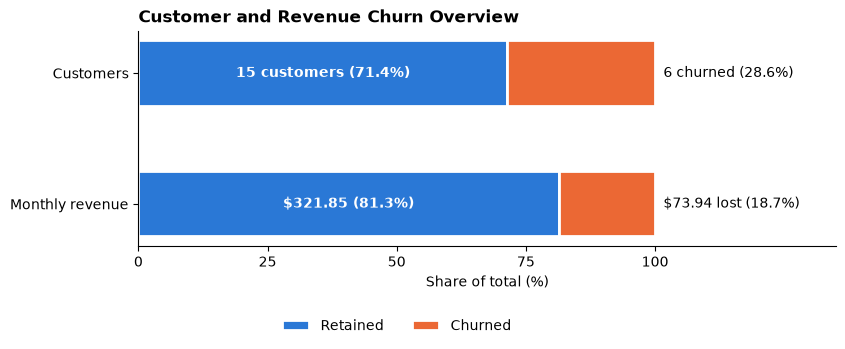

In [63]:
# Two Stacked bars (Matplotlib)

# Numbers behind the chart
total_users   = len(df_visual)
churned_users = df_visual['churn_flag'].sum()
total_revenue = df_visual['monthly_charges'].sum()
lost_revenue  = df_visual.loc[df_visual['churn_flag'] == 1, 'monthly_charges'].sum()

# List storing calculate values.
rows         = ['Monthly revenue', 'Customers']
churned_pct  = [lost_revenue / total_revenue * 100, churned_users / total_users * 100]
retained_revenue_pct   = 100 - churned_pct[0]    # first item: monthly revenue
retained_customers_pct = 100 - churned_pct[1]    # second item: customers

retained_pct = [retained_revenue_pct, retained_customers_pct]

plt.figure(figsize=(9, 2.8))

# Retained share first, then the churned share stacked to its right
bars_retained = plt.barh(rows, retained_pct, color=COLOR_RETAINED, label='Retained',
                         height=0.5, edgecolor='white', linewidth=2)
bars_churned  = plt.barh(rows, churned_pct, left=retained_pct, color=COLOR_CHURNED, label='Churned',
                         height=0.5, edgecolor='white', linewidth=2)

# Retained values inside the blue part, churned values to the right of the bar
plt.bar_label(bars_retained, label_type='center', color='white', fontweight='bold',
              labels=[f'${total_revenue - lost_revenue:,.2f} ({retained_pct[0]:.1f}%)',
                      f'{total_users - churned_users} customers ({retained_pct[1]:.1f}%)'])
plt.bar_label(bars_churned, padding=6,
              labels=[f'${lost_revenue:,.2f} lost ({churned_pct[0]:.1f}%)',
                      f'{churned_users} churned ({churned_pct[1]:.1f}%)'])

plt.title('Customer and Revenue Churn Overview' \
'')
plt.xlabel('Share of total (%)')
plt.xlim(0, 135)                                   # room for the labels on the right
plt.xticks([0, 25, 50, 75, 100])
plt.legend(loc='upper center', bbox_to_anchor=(0.37, -0.28), ncol=2)
plt.savefig('../images/churn_overview.png', dpi=150, bbox_inches='tight') # saving result to images folder
plt.show()

# Insight:
# - 6 of 21 customers churned (28.6%), taking $73.94 of $395.79 in monthly revenue (18.7%).
# - The revenue share lost is smaller than the customer share lost, so the customers
#   who left were paying less than average.



#### 5.2 Customer rate by plan, contract and channel

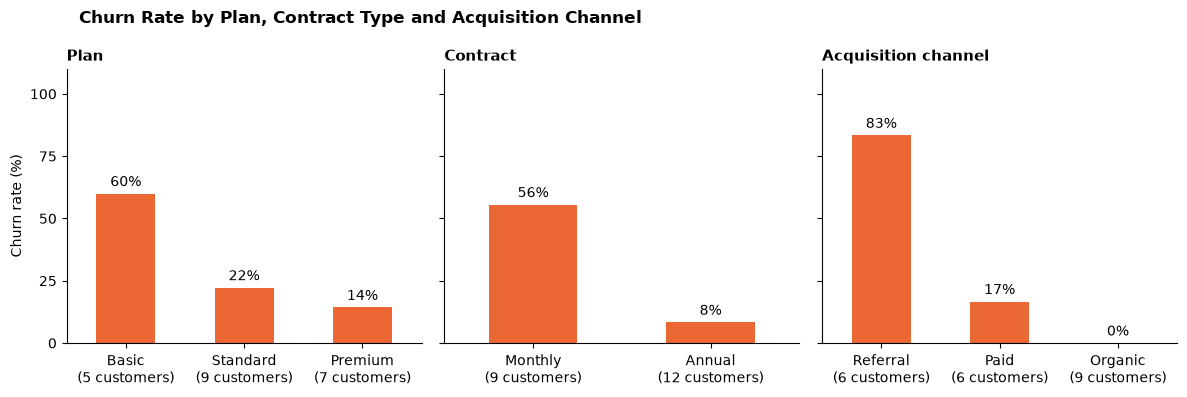

In [64]:
# Column Charts(Seaborn)

#This is a list of three recipes, one per chart. Each recipe holds three things:
# - The column to group by, for example 'plan_type'.
# - The order of the bars, left to right. Without it, seaborn would use the order the values happen to appear in the data.
# - The title for that small chart.
segments = [
    ('plan_type',['Basic', 'Standard', 'Premium'], 'Plan'),
    ('contract_type',['Monthly', 'Annual'],'Contract'),
    ('subscription_type', ['Referral', 'Paid', 'Organic'],'Acquisition channel'),
]



fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)   # 3 charts side by side, same y-axis

for ax, (column, order, panel_title) in zip(axes, segments):

    # Seaborn works out the average of churn_pct for each category: that is the churn rate
    sns.barplot(data=df_visual, x=column, y='churn_pct', order=order,
                color=COLOR_CHURNED, errorbar=None, width=0.5, saturation=1, ax=ax)

    ax.bar_label(ax.containers[0], fmt='%.0f%%', padding=3)        # churn rate on top of each bar

    # Show how many customers are behind each bar
    counts = df_visual[column].value_counts()
    ax.set_xticks(range(len(order)), labels=[f'{name}\n({counts[name]} customers)' for name in order])

    ax.set_title(panel_title, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Churn rate (%)')
    ax.set_ylim(0, 110)
    ax.set_yticks([0, 25, 50, 75, 100])

fig.suptitle('Churn Rate by Plan, Contract Type and Acquisition Channel', x=0.07, ha='left', fontweight='bold')
plt.tight_layout()
plt.savefig('../images/churn_by_segment.png', dpi=150, bbox_inches='tight') # saving result to images folder
plt.show()

# Insight:
# - Acquisition channel shows the widest gap: Referral 83% (5 of 6), Paid 17%, Organic 0%.
# - Monthly contracts churn at 56% against 8% for Annual.
# - Churn falls as the plan tier rises: Basic 60%, Standard 22%, Premium 14%.
# - The same five customers are both Referral and Monthly, so these two effects overlap.


#### 5.3 Churn rate by 'state'

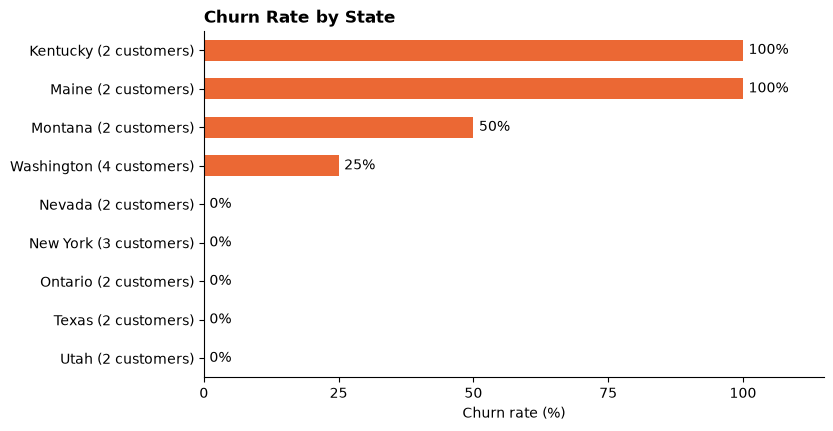

In [65]:
# Sorted Horizontal Bar Chart (seaborn)

# States from highest to lowest churn rate
state_order = df_visual.groupby('state')['churn_pct'].mean().sort_values(ascending=False).index

plt.figure(figsize=(8, 4.5))

ax = sns.barplot(data=df_visual, y='state', x='churn_pct', order=state_order,
                 color=COLOR_CHURNED, errorbar=None, width=0.55, saturation=1)

ax.bar_label(ax.containers[0], fmt='%.0f%%', padding=4)

# Show how many customers are behind each bar
counts = df_visual['state'].value_counts()
ax.set_yticks(range(len(state_order)), labels=[f'{state} ({counts[state]} customers)' for state in state_order])

plt.title('Churn Rate by State')
plt.xlabel('Churn rate (%)')
plt.ylabel('')
plt.xlim(0, 115)
plt.xticks([0, 25, 50, 75, 100])
plt.savefig('../images/churn_by_state.png', dpi=150, bbox_inches='tight') # saving result to images folder
plt.show()

# Insight:
# - Kentucky and Maine lost every customer (2 of 2 each): 4 of the 6 cancellations.
# - Five states have no churn at all.
# - Each state has only 2 to 4 customers, so these rates are indicative only.


In [66]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'num_complaints',
       'tenure_days', 'escalations_flag', 'churn_risk', 'has_complaint',
       'churn_pct'],
      dtype='str')

#### 5.4 Cancellation reasons

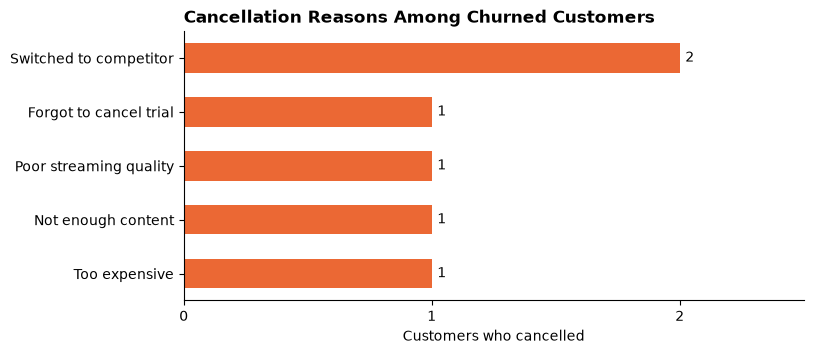

In [67]:
# Horizontal Bar chart (Seaborn)
# Count occurances

#Filter churn records
churned = df_visual[df_visual['churn_flag'] == 1]

reason_order = churned['cancellation_reason'].value_counts().index     # most common reason first

plt.figure(figsize=(8, 3.5))

# countplot counts the rows for each reason, so no groupby is needed
ax = sns.countplot(data=churned, y='cancellation_reason', order=reason_order,
                   color=COLOR_CHURNED, width=0.55, saturation=1)

ax.bar_label(ax.containers[0], padding=4)

plt.title('Cancellation Reasons Among Churned Customers')
plt.xlabel('Customers who cancelled')
plt.ylabel('')
plt.xlim(0, 2.5)
plt.xticks([0, 1, 2])
plt.savefig('../images/cancellation_reasons.png', dpi=150, bbox_inches='tight') # saving result to images folder
plt.show()

# Insight:
# - 'Switched to competitor' is the only reason given twice (2 of 6 cancellations).
# - The other four reasons appear once each, covering price, trial, content and quality.
# - With six cancellations, each reason is one or two customers.


#### 5.5 Complaints and timing

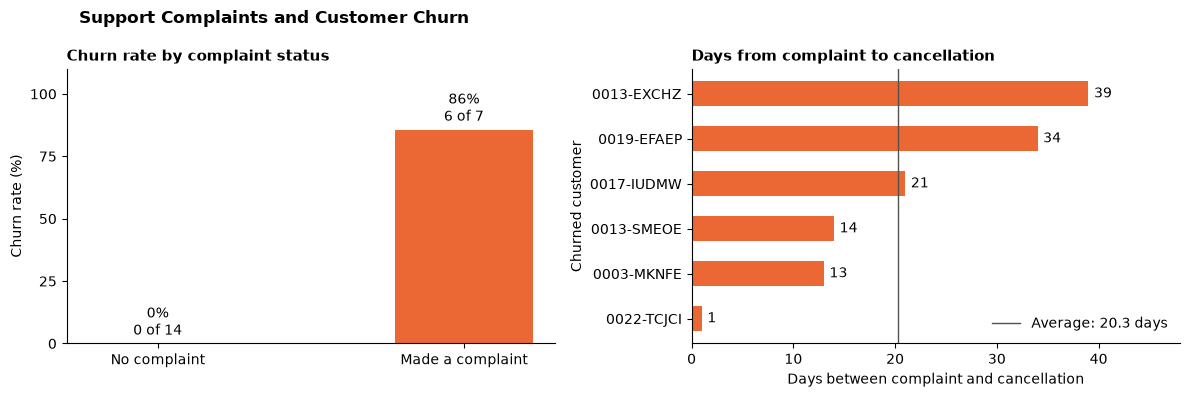

In [68]:
df_visual['complaint_status'] = np.where(df_visual['num_complaints'].notna(), 'Made a complaint', 'No complaint')

# Churn rate, churned customers and total customers for each complaint status
by_complaint = df_visual.groupby('complaint_status')['churn_flag'].agg(churn_rate='mean', churned='sum', customers='count')
by_complaint['churn_rate'] = by_complaint['churn_rate'] * 100
by_complaint = by_complaint.reindex(['No complaint', 'Made a complaint'])

# Days from complaint to cancellation, for the customers who churned
timing = df_visual[df_visual['churn_flag'] == 1].copy()
timing['days_to_cancel'] = (timing['cancellation_date'] - timing['complaint_date']).dt.days
timing = timing.sort_values('days_to_cancel')
average_days = timing['days_to_cancel'].mean()

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4))

# Left: does a complaint go with churn?
bars = ax_left.bar(by_complaint.index, by_complaint['churn_rate'], color=COLOR_CHURNED, width=0.45)
labels = [f'{row.churn_rate:.0f}%\n{row.churned:.0f} of {row.customers:.0f}' for row in by_complaint.itertuples()]
ax_left.bar_label(bars, labels=labels, padding=3)
ax_left.set_title('Churn rate by complaint status', fontsize=11)
ax_left.set_ylabel('Churn rate (%)')
ax_left.set_ylim(0, 110)
ax_left.set_yticks([0, 25, 50, 75, 100])

# Right: how long before cancelling did they complain?
bars = ax_right.barh(timing['customerid'], timing['days_to_cancel'], color=COLOR_CHURNED, height=0.55)
ax_right.bar_label(bars, padding= 4)
ax_right.axvline(average_days, color=COLOR_NOTE, linewidth=1, label=f'Average: {average_days:.1f} days') # line-marker: avg days from complaint to cancellation
ax_right.set_title('Days from complaint to cancellation', fontsize=11)
ax_right.set_xlabel('Days between complaint and cancellation')
ax_right.set_ylabel('Churned customer')
ax_right.set_xlim(0, 48)
ax_right.legend(loc='lower right')

fig.suptitle('Support Complaints and Customer Churn', x=0.07, ha='left', fontweight='bold')
plt.tight_layout()
plt.savefig('../images/complaints_churn.png', dpi=150, bbox_inches='tight')# saving result to images folder
plt.show()

# Insight:
# - 6 of the 7 customers who complained went on to cancel (86%); none of the 14 who
#   never complained did.
# - The complaint came 1 to 39 days before the cancellation, 20.3 days on average.
#   That gap is the window for a retention offer.


#### 5.6 Active customers by churn score

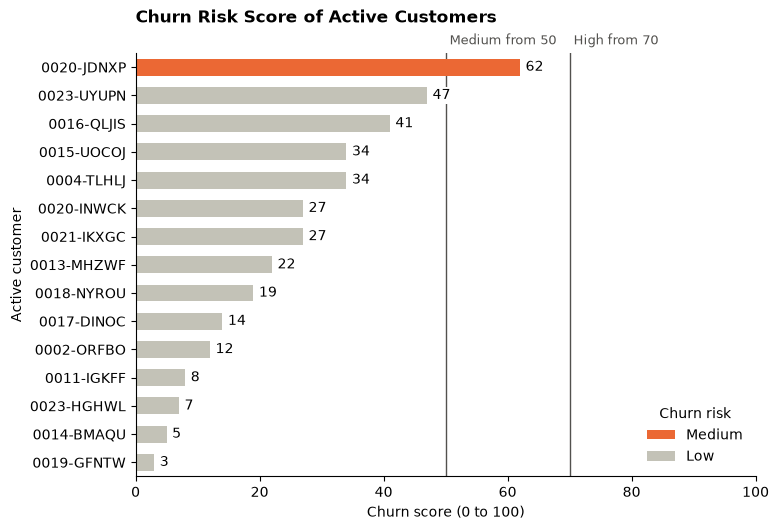

In [69]:
# Horizontal bar chart (seaborn)

active = df_visual[df_visual['churn_flag'] == 0].sort_values('churn_score', ascending=False)   # highest score first

risk_colors = {'Low': COLOR_NEUTRAL, 'Medium': COLOR_CHURNED, 'High': '#d03b3b'}

plt.figure(figsize=(8, 5.5))

# hue colours each bar by its risk band and builds the legend automatically
ax = sns.barplot(data=active, y='customerid', x='churn_score', hue='churn_risk',
                 palette=risk_colors, dodge=False, width=0.6, saturation=1)

for container in ax.containers:                                     # one group of bars per risk band
    ax.bar_label(container, padding=4, bbox=dict(facecolor='white', edgecolor='none', pad=1))

# Where the risk bands start
plt.axvline(50, color=COLOR_NOTE, linewidth=1, zorder=0)
plt.axvline(70, color=COLOR_NOTE, linewidth=1, zorder=0)
plt.text(50, -0.7, ' Medium from 50', color=COLOR_NOTE, fontsize=9, va='bottom')
plt.text(70, -0.7, ' High from 70', color=COLOR_NOTE, fontsize=9, va='bottom')

plt.title('Churn Risk Score of Active Customers', pad=22)
plt.xlabel('Churn score (0 to 100)')
plt.ylabel('Active customer')
plt.xlim(0, 100)
plt.legend(title='Churn risk', loc='lower right')
plt.savefig('../images/churn_risk_active_customer.png', dpi=150, bbox_inches='tight')# saving result to images folder
plt.show()

# Insight:
# - 0020-JDNXP (score 62) is the only active customer above the Medium threshold
#   and is the first candidate for a retention offer.
# - The next highest, 0023-UYUPN (47), sits just under the threshold and is worth watching.
# - No active customer is in the High band; all six High-band customers have already churned.


#### 5.7 Cancellations by month

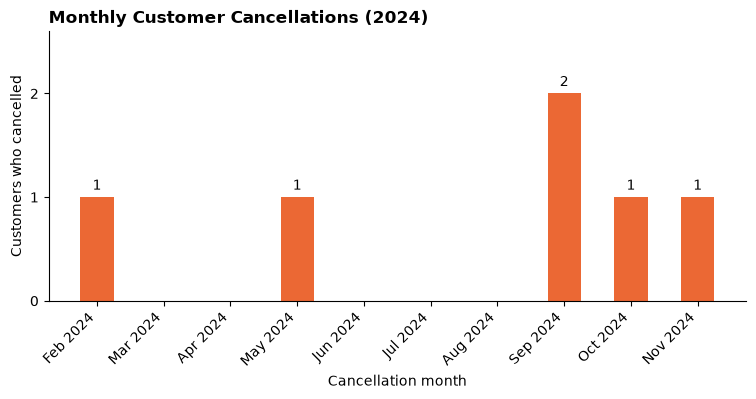

In [70]:
cancel_month = df_visual.loc[df_visual['churn_flag'] == 1, 'cancellation_date'].dt.to_period('M')
monthly_churn = cancel_month.value_counts().sort_index()

# Add the months with no cancellations, so the time axis has no gaps
all_months = pd.period_range(monthly_churn.index.min(), monthly_churn.index.max(), freq='M')
monthly_churn = monthly_churn.reindex(all_months, fill_value=0)

plt.figure(figsize=(9, 3.5))

bars = plt.bar(monthly_churn.index.strftime('%b %Y'), monthly_churn.values, color=COLOR_CHURNED, width=0.5)
plt.bar_label(bars, labels=[str(v) if v > 0 else '' for v in monthly_churn.values], padding=3)

plt.title('Monthly Customer Cancellations (2024)')
plt.xlabel('Cancellation month')
plt.ylabel('Customers who cancelled')
plt.yticks([0, 1, 2])
plt.ylim(0, 2.6)
plt.xticks(rotation=45, ha='right')
plt.savefig('../images/monthly_cancellation.png', dpi=150, bbox_inches='tight')# saving result to images folder
plt.show()

# Insight:
# - Cancellations cluster late in the year: 4 of 6 fall in September to November 2024.
# - February and May 2024 had one each; six of the ten months had none.
# - Six events are too few to call this a seasonal pattern.
